In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("bestsellers with categories.csv")


df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [22]:
# Inspecting the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

# Standardizing column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Removing exact duplicate rows
df = df.drop_duplicates().copy()

# Clean text columns if present
for col in ["name", "author", "genre"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Converting numeric columns safely
for col in ["user_rating", "reviews", "price", "year"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nMissing values after conversion:")
print(df.isnull().sum())

print("\nUpdated data types:")
print(df.dtypes)

df.head()

Dataset shape: (550, 7)

Column names:
['Name', 'Author', 'User Rating', 'Reviews', 'Price', 'Year', 'Genre']

Missing values:
Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64

Duplicate rows: 0

Data types:
Name               str
Author             str
User Rating    float64
Reviews          int64
Price            int64
Year             int64
Genre              str
dtype: object

Missing values after conversion:
name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64

Updated data types:
name            string
author          string
user_rating    float64
reviews          int64
price            int64
year             int64
genre           string
dtype: object


,name,author,user_rating,reviews,price,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


Top 10 authors by bestseller appearances:
author
Jeff Kinney                           12
Suzanne Collins                       11
Rick Riordan                          11
Gary Chapman                          11
American Psychological Association    10
Dr. Seuss                              9
Gallup                                 9
Rob Elliott                            8
Stephenie Meyer                        7
Dav Pilkey                             7
Name: count, dtype: int64[pyarrow]


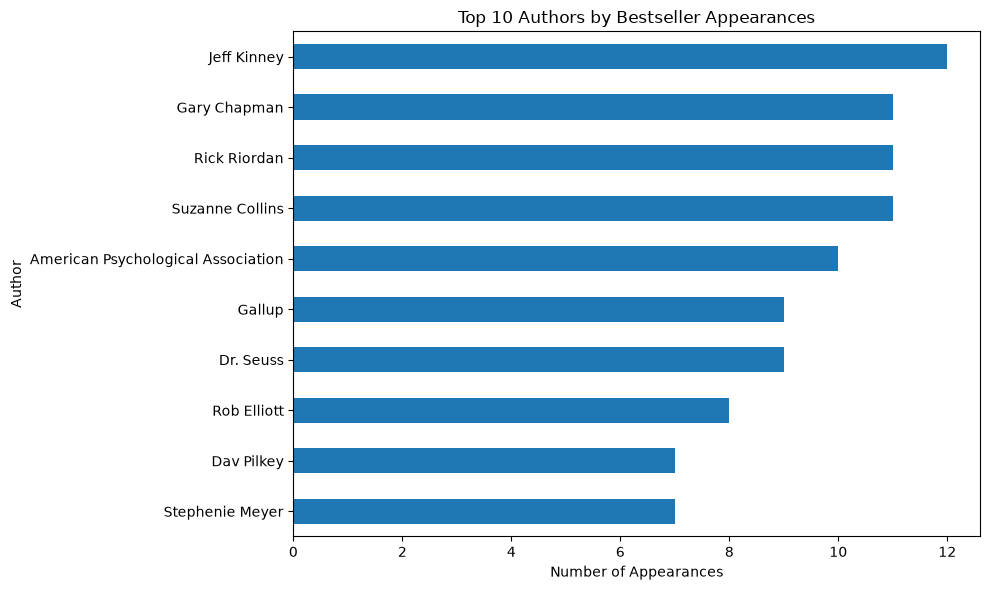

In [23]:
# Counting bestseller appearances by author
top_authors = df["author"].value_counts().head(10)

print("Top 10 authors by bestseller appearances:")
print(top_authors)

# Visualize the results
top_authors.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Authors by Bestseller Appearances")
plt.xlabel("Number of Appearances")
plt.ylabel("Author")
plt.tight_layout()
plt.show()

             book_records  average_rating  average_price  average_reviews
genre                                                                    
Fiction               240            4.65          10.85         15683.79
Non Fiction           310            4.60          14.84          9065.15


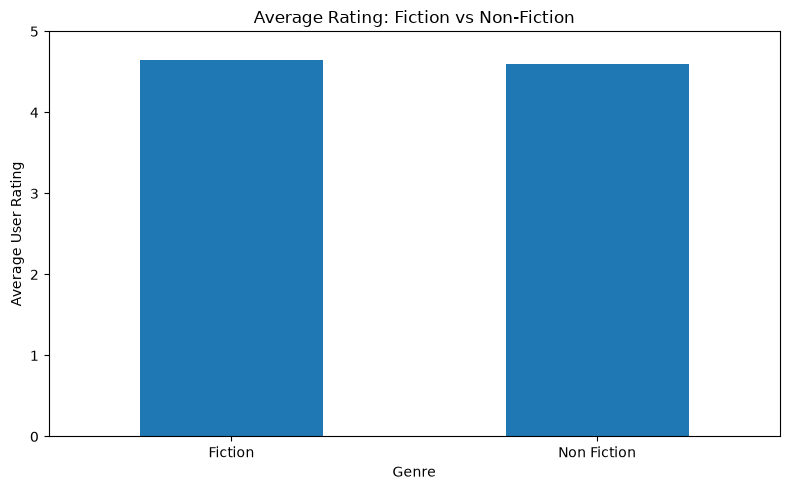

In [24]:
genre_analysis = df.groupby("genre").agg(
    book_records=("name", "count"),
    average_rating=("user_rating", "mean"),
    average_price=("price", "mean"),
    average_reviews=("reviews", "mean")
).round(2)

print(genre_analysis)

# Compare average ratings
genre_analysis["average_rating"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Rating: Fiction vs Non-Fiction")
plt.xlabel("Genre")
plt.ylabel("Average User Rating")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

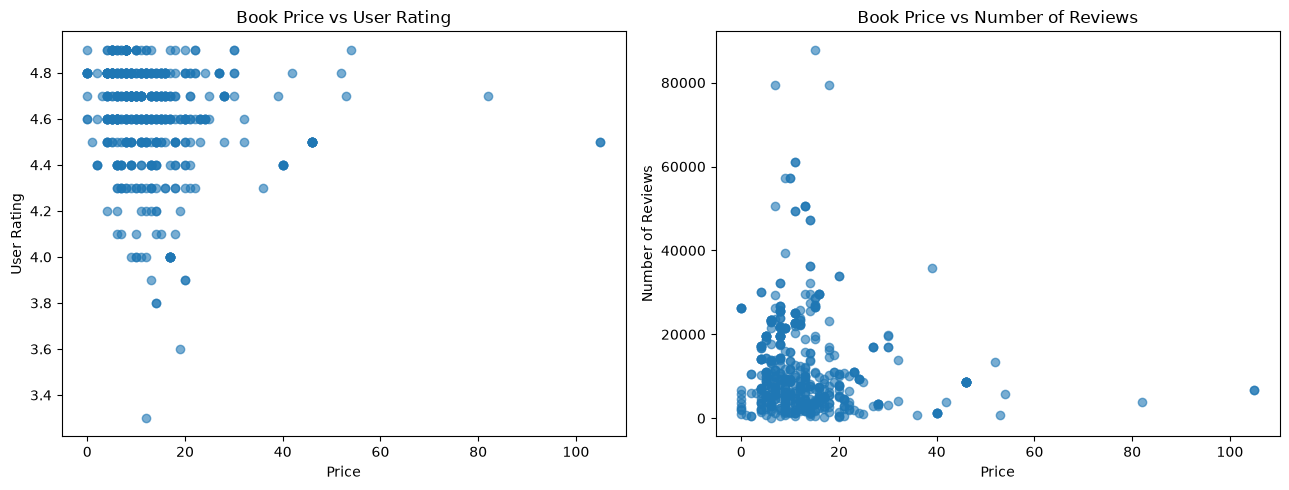

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Price vs rating
axes[0].scatter(
    df["price"],
    df["user_rating"],
    alpha=0.6
)

axes[0].set_title("Book Price vs User Rating")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("User Rating")

# Price vs reviews
axes[1].scatter(
    df["price"],
    df["reviews"],
    alpha=0.6
)

axes[1].set_title("Book Price vs Number of Reviews")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

      book_records  average_price
year                             
2009            50          15.40
2010            50          13.48
2011            50          15.10
2012            50          15.30
2013            50          14.60
2014            50          14.64
2015            50          10.42
2016            50          13.18
2017            50          11.38
2018            50          10.52
2019            50          10.08


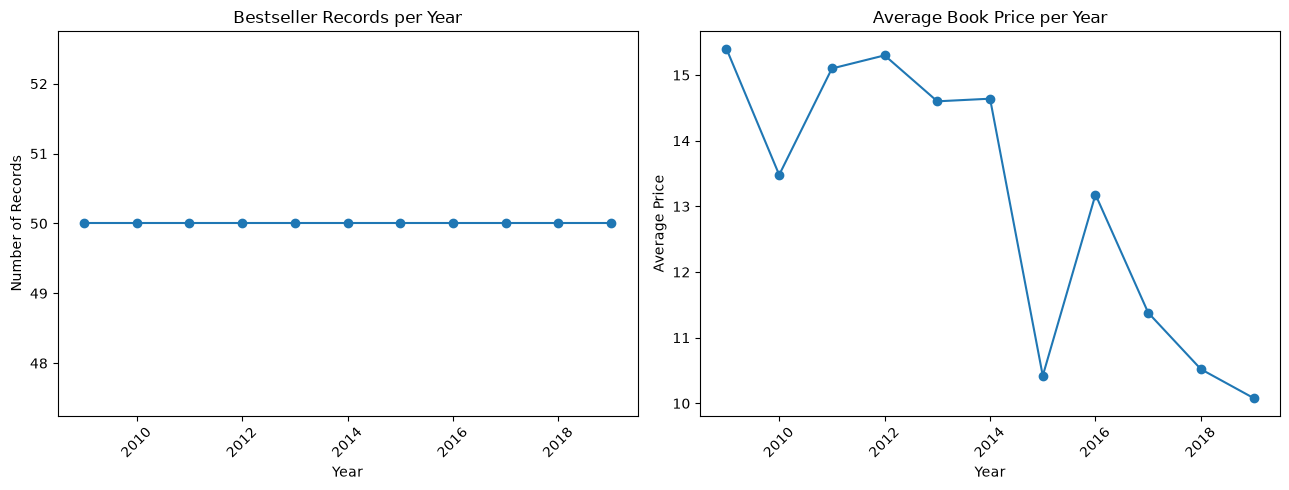

In [26]:
yearly_trends = df.groupby("year").agg(
    book_records=("name", "count"),
    average_price=("price", "mean")
).round(2)

print(yearly_trends)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Number of records per year
axes[0].plot(
    yearly_trends.index,
    yearly_trends["book_records"],
    marker="o"
)

axes[0].set_title("Bestseller Records per Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Records")

# Average price per year
axes[1].plot(
    yearly_trends.index,
    yearly_trends["average_price"],
    marker="o"
)

axes[1].set_title("Average Book Price per Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average Price")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Correlation matrix:
             reviews  user_rating  price
reviews        1.000       -0.002 -0.109
user_rating   -0.002        1.000 -0.133
price         -0.109       -0.133  1.000


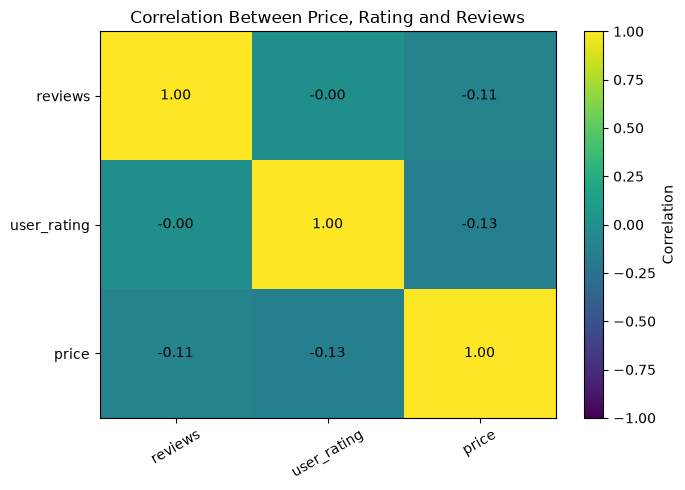

In [27]:
numeric_cols = ["reviews", "user_rating", "price"]

correlation_matrix = df[numeric_cols].corr()

print("Correlation matrix:")
print(correlation_matrix.round(3))

# Visualize the correlations
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_cols)),
    numeric_cols,
    rotation=30
)

plt.yticks(
    range(len(numeric_cols)),
    numeric_cols
)

# Display correlation values
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Between Price, Rating and Reviews")
plt.tight_layout()
plt.show()